#WEEK 2 - ML Roadmap

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

#Common preparation code

In [30]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

titanic = sns.load_dataset('titanic')

titanic_X = titanic[
    ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
]
titanic_y = titanic['survived']

wine = load_wine()
wine_X = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_y = pd.Series(wine.target)

cancer = load_breast_cancer()
cancer_X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
cancer_y = pd.Series(cancer.target)

datasets = {
    'Titanic': (titanic_X, titanic_y),
    'Wine': (wine_X, wine_y),
    'Breast Cancer': (cancer_X, cancer_y)
}

splits = {}

for name, (X, y) in datasets.items():

    valid = y.notna()
    X = X.loc[valid]
    y = y.loc[valid]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    numeric_features = X.select_dtypes(include=['number']).columns.tolist()
    categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ])

        transformers.append(
            ('num', numeric_pipeline, numeric_features)
        )

    if categorical_features:
        categorical_pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ))
        ])

        transformers.append(
            ('cat', categorical_pipeline, categorical_features)
        )

    preprocessor = ColumnTransformer(transformers)

    splits[name] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'preprocessor': preprocessor
    }

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


#Decision Tree


Decision Tree - Titanic
Best Parameters: {'classifier__max_depth': 7, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
Best CV F1: 0.8043
              precision    recall  f1-score   support

           0       0.78      0.92      0.84       110
           1       0.82      0.58      0.68        69

    accuracy                           0.79       179
   macro avg       0.80      0.75      0.76       179
weighted avg       0.79      0.79      0.78       179


Decision Tree - Wine
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best CV F1: 0.9021
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        12
           1       0.88      1.00      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95    

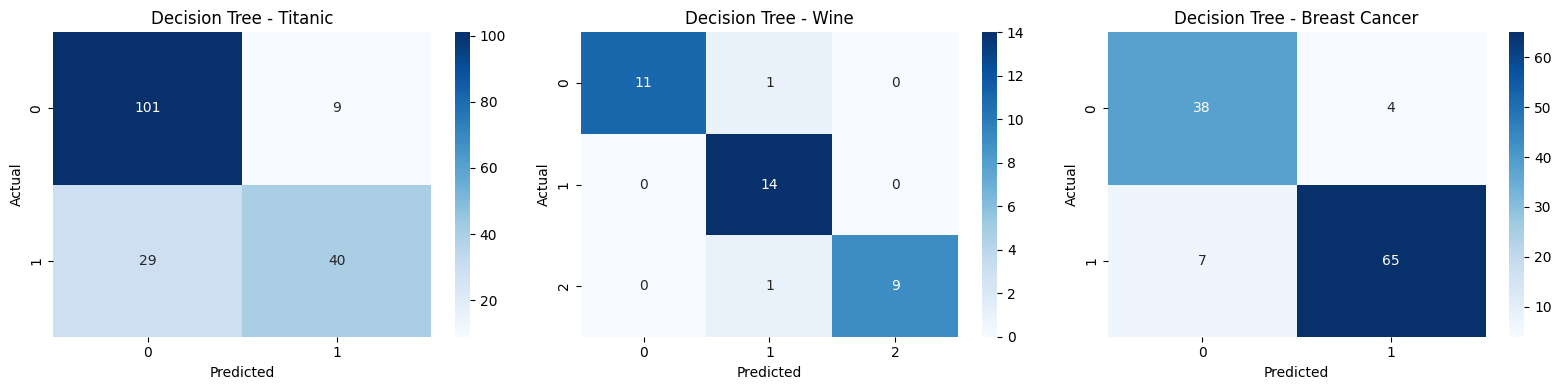

In [32]:

decision_tree_params = {
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

decision_tree_results = []
decision_tree_models = {}

for dataset_name, data in splits.items():

    pipeline = Pipeline([
        ('preprocessor', data['preprocessor']),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ])

    grid = GridSearchCV(
        pipeline,
        decision_tree_params,
        scoring='f1_weighted',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(data['X_train'], data['y_train'])

    best_model = grid.best_estimator_
    y_pred = best_model.predict(data['X_test'])

    decision_tree_models[dataset_name] = best_model

    result = {
        'Dataset': dataset_name,
        'Best CV F1': grid.best_score_,
        'Accuracy': accuracy_score(data['y_test'], y_pred),
        'Precision': precision_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Best Parameters': grid.best_params_
    }

    decision_tree_results.append(result)

    print(f'\nDecision Tree - {dataset_name}')
    print('Best Parameters:', grid.best_params_)
    print('Best CV F1:', round(grid.best_score_, 4))
    print(classification_report(
        data['y_test'], y_pred, zero_division=0
    ))

decision_tree_df = pd.DataFrame(decision_tree_results)

print('\nDECISION TREE PERFORMANCE')
print(decision_tree_df.drop(columns='Best Parameters').round(4).to_string(index=False))

best_dt = decision_tree_df.loc[decision_tree_df['Best CV F1'].idxmax()]

print('\nBest Decision Tree Dataset:', best_dt['Dataset'])
print('Best CV F1:', round(best_dt['Best CV F1'], 4))

# Decision Tree visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, dataset_name in zip(axes, splits):

    data = splits[dataset_name]
    model = decision_tree_models[dataset_name]

    y_pred = model.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)

    ax.set_title(f'Decision Tree - {dataset_name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


#K-Nearest Neighbors (KNN)


KNN - Titanic
Best Parameters: {'classifier__n_neighbors': 9, 'classifier__p': 1, 'classifier__weights': 'uniform'}
Best CV F1: 0.81
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       110
           1       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179


KNN - Wine
Best Parameters: {'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'uniform'}
Best CV F1: 0.979
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


KNN - Breast Cancer
Best 

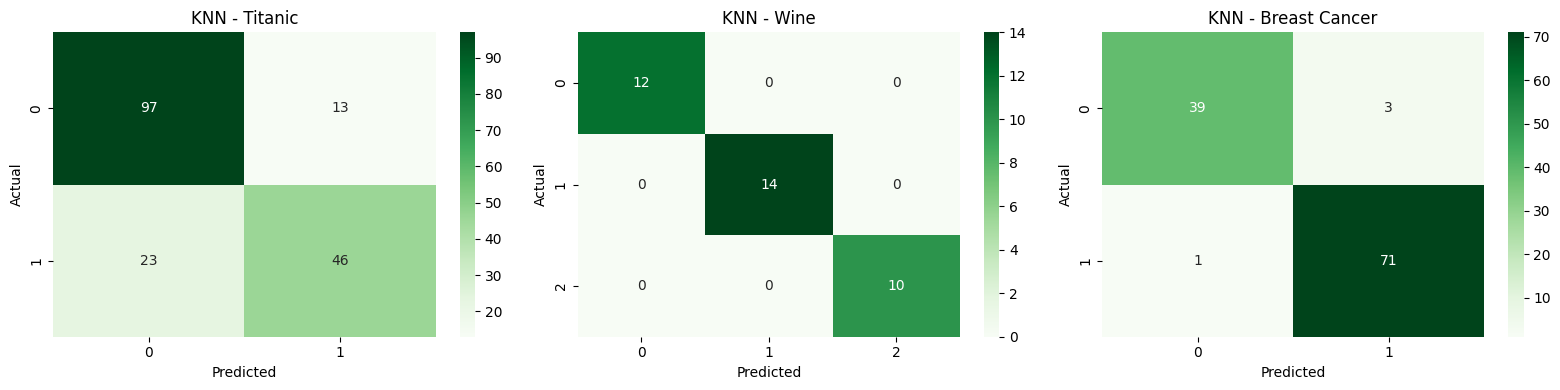

In [33]:

knn_params = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2]
}

knn_results = []
knn_models = {}

for dataset_name, data in splits.items():

    pipeline = Pipeline([
        ('preprocessor', data['preprocessor']),
        ('classifier', KNeighborsClassifier())
    ])

    grid = GridSearchCV(
        pipeline,
        knn_params,
        scoring='f1_weighted',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(data['X_train'], data['y_train'])

    best_model = grid.best_estimator_
    y_pred = best_model.predict(data['X_test'])

    knn_models[dataset_name] = best_model

    result = {
        'Dataset': dataset_name,
        'Best CV F1': grid.best_score_,
        'Accuracy': accuracy_score(data['y_test'], y_pred),
        'Precision': precision_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Best Parameters': grid.best_params_
    }

    knn_results.append(result)

    print(f'\nKNN - {dataset_name}')
    print('Best Parameters:', grid.best_params_)
    print('Best CV F1:', round(grid.best_score_, 4))
    print(classification_report(
        data['y_test'], y_pred, zero_division=0
    ))

knn_df = pd.DataFrame(knn_results)

print('\nKNN PERFORMANCE')
print(knn_df.drop(columns='Best Parameters').round(4).to_string(index=False))

best_knn = knn_df.loc[knn_df['Best CV F1'].idxmax()]

print('\nBest KNN Dataset:', best_knn['Dataset'])
print('Best CV F1:', round(best_knn['Best CV F1'], 4))

# KNN visualization

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, dataset_name in zip(axes, splits):

    data = splits[dataset_name]
    model = knn_models[dataset_name]

    y_pred = model.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax)

    ax.set_title(f'KNN - {dataset_name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


#Naive Bayes


Naive Bayes - Titanic
Best Parameters: {'classifier__var_smoothing': 1e-09}
Best CV F1: 0.7941
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       110
           1       0.74      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179


Naive Bayes - Wine
Best Parameters: {'classifier__var_smoothing': 1e-09}
Best CV F1: 0.9724
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.93      0.96        14
           2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36


Naive Bayes - Breast Cancer
Best Parameters: {'classifier__var_smoothing': 1e-09}
Best CV F1: 0.9339
 

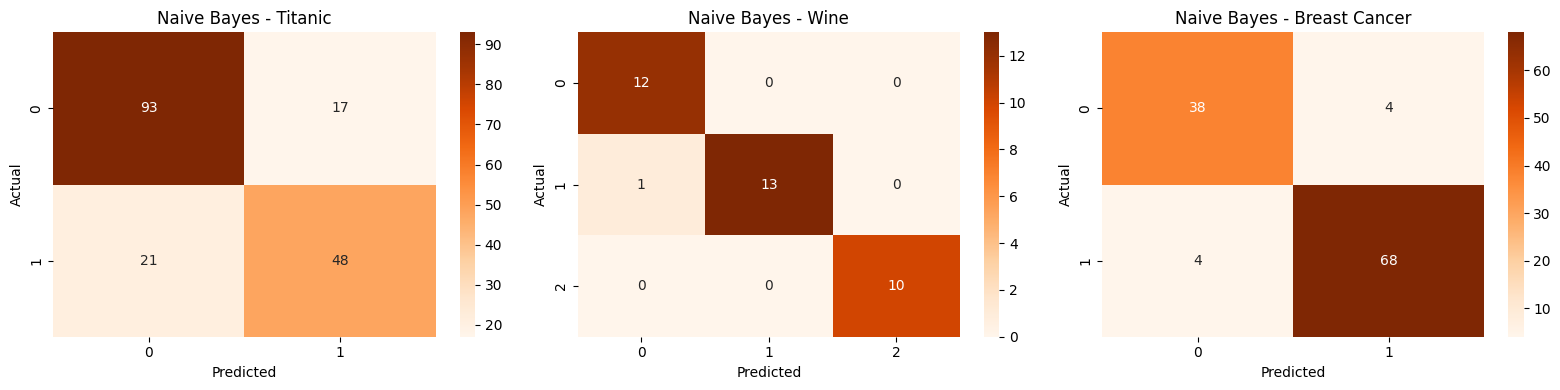

In [34]:

nb_params = {
    'classifier__var_smoothing': [
        1e-9, 1e-8, 1e-7, 1e-6, 1e-5
    ]
}

nb_results = []
nb_models = {}

for dataset_name, data in splits.items():

    pipeline = Pipeline([
        ('preprocessor', data['preprocessor']),
        ('classifier', GaussianNB())
    ])

    grid = GridSearchCV(
        pipeline,
        nb_params,
        scoring='f1_weighted',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(data['X_train'], data['y_train'])

    best_model = grid.best_estimator_
    y_pred = best_model.predict(data['X_test'])

    nb_models[dataset_name] = best_model

    result = {
        'Dataset': dataset_name,
        'Best CV F1': grid.best_score_,
        'Accuracy': accuracy_score(data['y_test'], y_pred),
        'Precision': precision_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            data['y_test'], y_pred,
            average='weighted', zero_division=0
        ),
        'Best Parameters': grid.best_params_
    }

    nb_results.append(result)

    print(f'\nNaive Bayes - {dataset_name}')
    print('Best Parameters:', grid.best_params_)
    print('Best CV F1:', round(grid.best_score_, 4))
    print(classification_report(
        data['y_test'], y_pred, zero_division=0
    ))

nb_df = pd.DataFrame(nb_results)

print('\nNAIVE BAYES PERFORMANCE')
print(nb_df.drop(columns='Best Parameters').round(4).to_string(index=False))

best_nb = nb_df.loc[nb_df['Best CV F1'].idxmax()]

print('\nBest Naive Bayes Dataset:', best_nb['Dataset'])
print('Best CV F1:', round(best_nb['Best CV F1'], 4))


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, dataset_name in zip(axes, splits):

    data = splits[dataset_name]
    model = nb_models[dataset_name]

    y_pred = model.predict(data['X_test'])

    cm = confusion_matrix(data['y_test'], y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax)

    ax.set_title(f'Naive Bayes - {dataset_name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


# Performance comparison All three classifiers on all three datasets


========== BEST DATASET FOR EACH CLASSIFIER ==========
Decision Tree: Best on Breast Cancer | CV F1: 0.9385 | Test F1: 0.9041
KNN: Best on Wine | CV F1: 0.9790 | Test F1: 1.0000
Naive Bayes: Best on Wine | CV F1: 0.9724 | Test F1: 0.9723

========== COMPLETE CLASSIFIER COMPARISON ==========
      Dataset    Classifier  CV F1 Score  Accuracy  Precision  Recall  F1 Score
      Titanic Decision Tree       0.8043    0.7877     0.7921  0.7877    0.7786
         Wine Decision Tree       0.9021    0.9444     0.9514  0.9444    0.9450
Breast Cancer Decision Tree       0.9385    0.9035     0.9061  0.9035    0.9041
      Titanic           KNN       0.8100    0.7989     0.7973  0.7989    0.7954
         Wine           KNN       0.9790    1.0000     1.0000  1.0000    1.0000
Breast Cancer           KNN       0.9713    0.9649     0.9652  0.9649    0.9647
      Titanic   Naive Bayes       0.7941    0.7877     0.7860  0.7877    0.7864
         Wine   Naive Bayes       0.9724    0.9722     0.9744  0.97

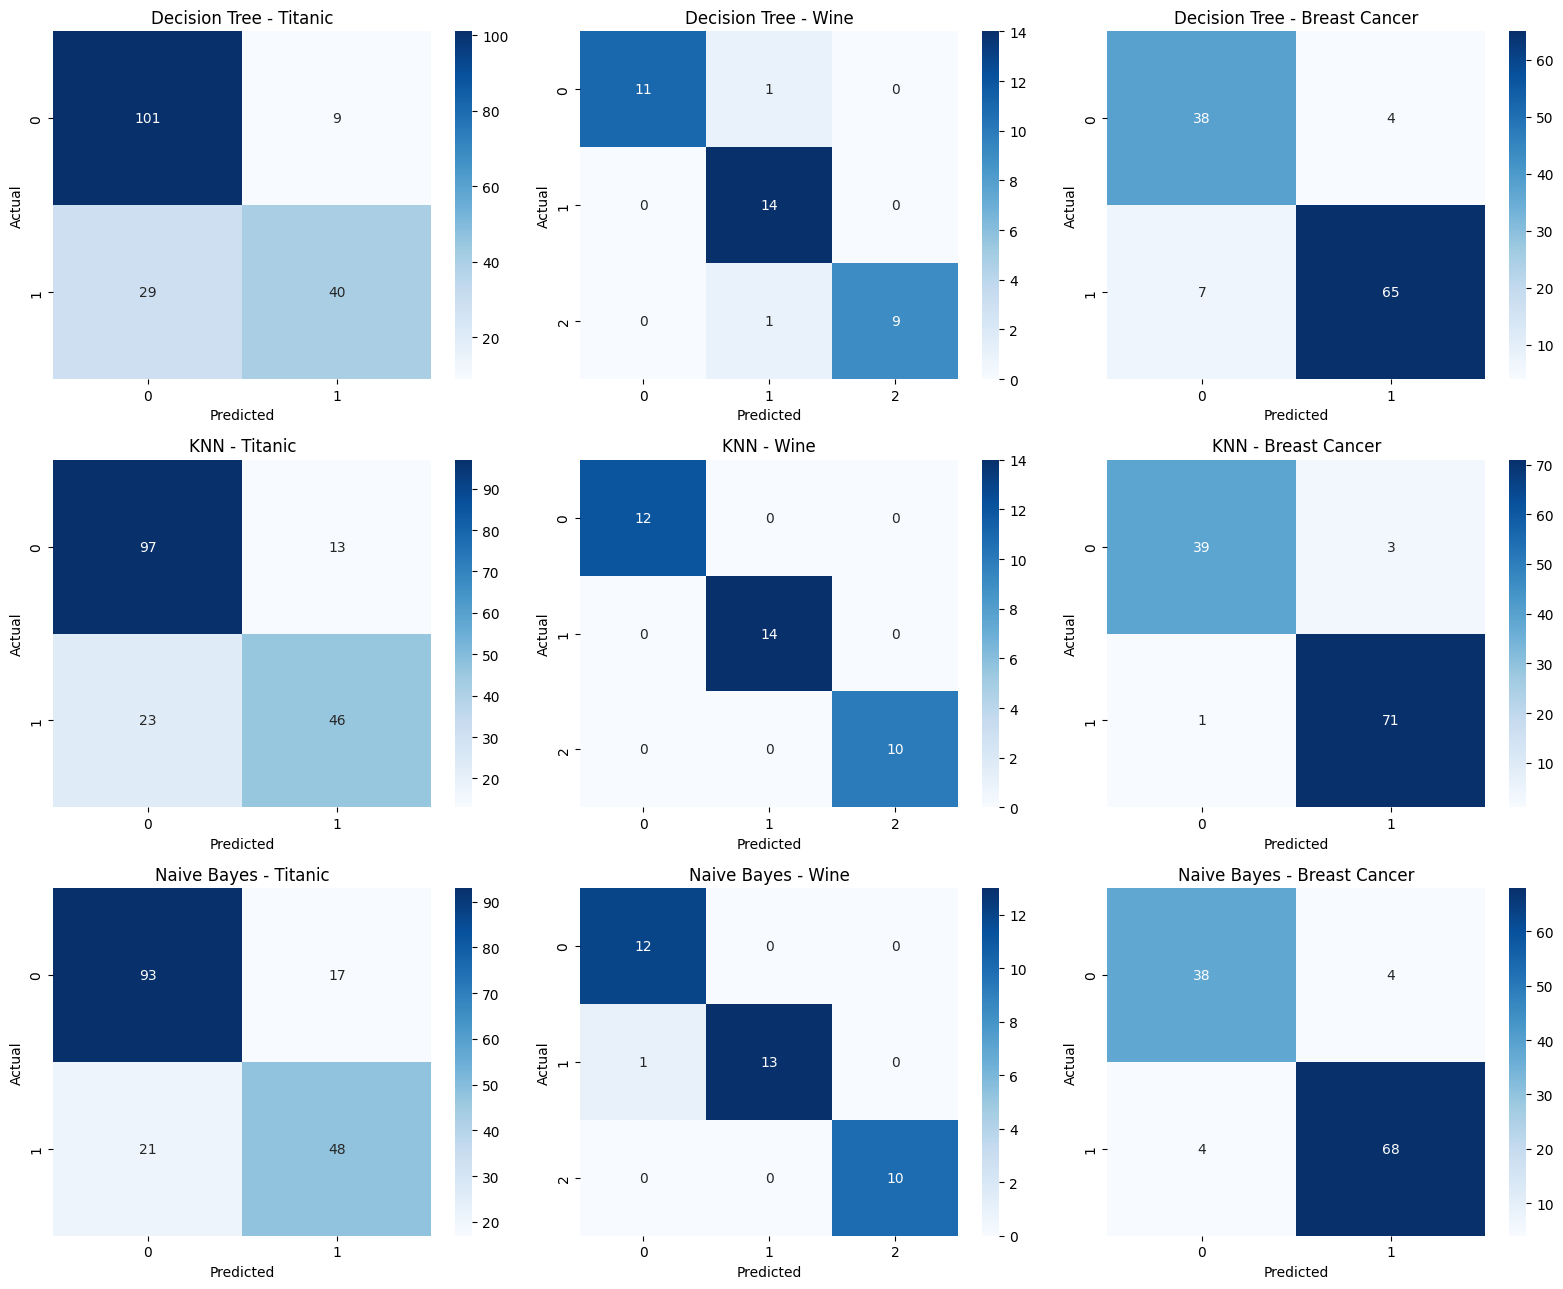

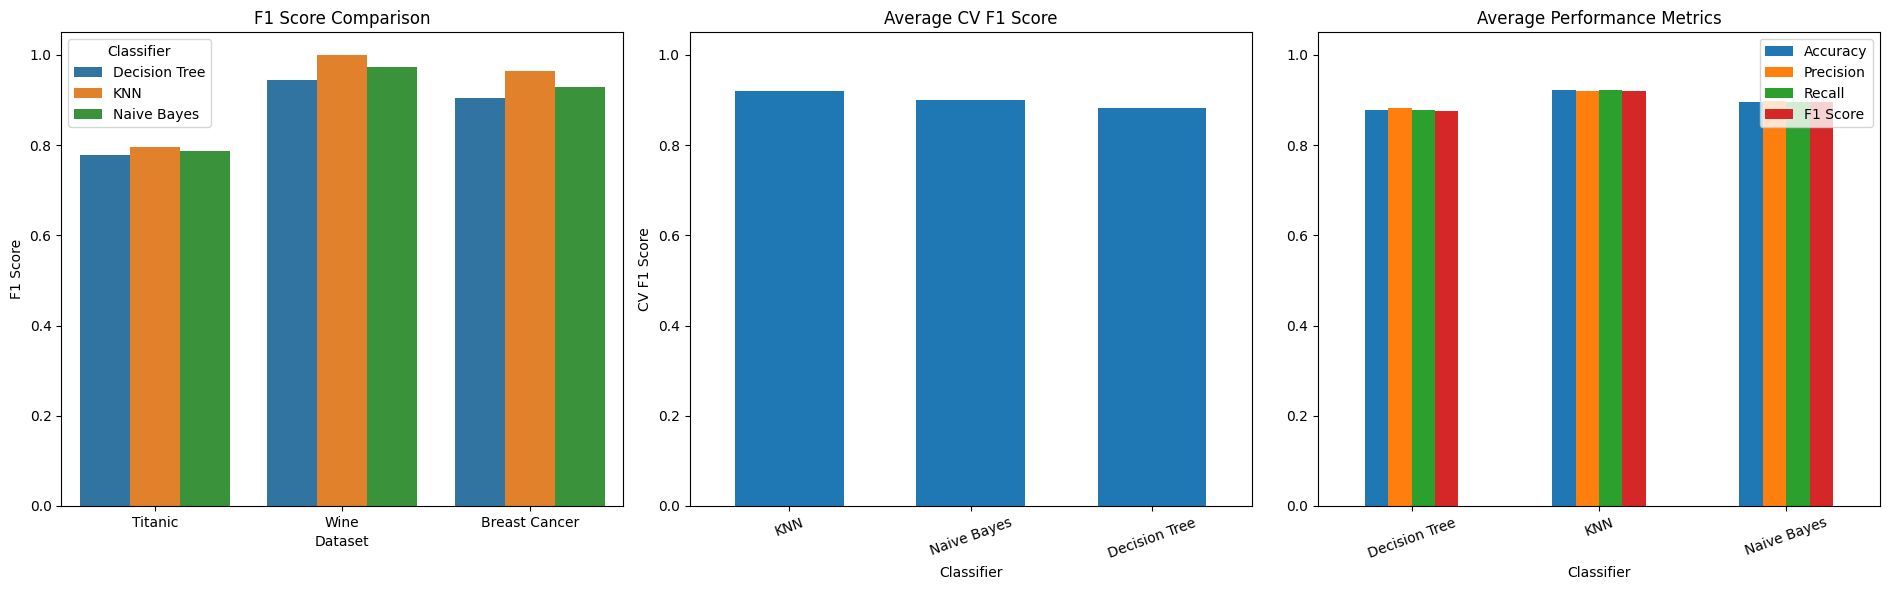

In [36]:
# ============================================================
# 1. COMBINE INDIVIDUAL CLASSIFIER RESULTS
# ============================================================

individual_results = pd.concat(
    [decision_tree_df, knn_df, nb_df],
    ignore_index=True
)


# ============================================================
# 2. BEST DATASET FOR EACH CLASSIFIER
# ============================================================

print("\n========== BEST DATASET FOR EACH CLASSIFIER ==========")

classifier_results = {
    'Decision Tree': decision_tree_df,
    'KNN': knn_df,
    'Naive Bayes': nb_df
}

for model_name, results_df in classifier_results.items():

    best = results_df.loc[
        results_df['Best CV F1'].idxmax()
    ]

    print(
        f"{model_name}: Best on {best['Dataset']} | "
        f"CV F1: {best['Best CV F1']:.4f} | "
        f"Test F1: {best['F1 Score']:.4f}"
    )


# ============================================================
# 3. CREATE COMPLETE CLASSIFIER COMPARISON TABLE
# ============================================================

all_results = []

for model_name, results in [
    ('Decision Tree', decision_tree_results),
    ('KNN', knn_results),
    ('Naive Bayes', nb_results)
]:

    for result in results:

        all_results.append({
            'Dataset': result['Dataset'],
            'Classifier': model_name,
            'CV F1 Score': result['Best CV F1'],
            'Accuracy': result['Accuracy'],
            'Precision': result['Precision'],
            'Recall': result['Recall'],
            'F1 Score': result['F1 Score']
        })

comparison_df = pd.DataFrame(all_results)

print("\n========== COMPLETE CLASSIFIER COMPARISON ==========")

print(
    comparison_df.round(4).to_string(index=False)
)


# ============================================================
# 4. BEST CLASSIFIER FOR EACH DATASET
# ============================================================

print("\n========== BEST CLASSIFIER FOR EACH DATASET ==========")

for dataset_name in datasets:

    subset = comparison_df[
        comparison_df['Dataset'] == dataset_name
    ]

    best = subset.loc[
        subset['CV F1 Score'].idxmax()
    ]

    print(
        f"{dataset_name}: {best['Classifier']} | "
        f"CV F1: {best['CV F1 Score']:.4f} | "
        f"Test F1: {best['F1 Score']:.4f}"
    )


# ============================================================
# 5. OVERALL BEST CLASSIFIER-DATASET COMBINATION
# ============================================================

print("\n========== OVERALL BEST CLASSIFIER-DATASET COMBINATION ==========")

overall_best = comparison_df.loc[
    comparison_df['CV F1 Score'].idxmax()
]

print("Dataset:", overall_best['Dataset'])
print("Classifier:", overall_best['Classifier'])
print("CV F1 Score:", round(overall_best['CV F1 Score'], 4))
print("Test Accuracy:", round(overall_best['Accuracy'], 4))
print("Test F1 Score:", round(overall_best['F1 Score'], 4))


# ============================================================
# 6. AVERAGE CROSS-VALIDATION PERFORMANCE BY CLASSIFIER
# ============================================================

print("\n========== AVERAGE CV PERFORMANCE BY CLASSIFIER ==========")

average_results = (
    comparison_df.groupby('Classifier')['CV F1 Score']
    .mean()
    .sort_values(ascending=False)
)

print(average_results.round(4))


# ============================================================
# 7. BEST OVERALL CLASSIFIER
# ============================================================

print("\n========== BEST OVERALL CLASSIFIER ==========")

best_classifier = average_results.index[0]

print("Best Classifier:", best_classifier)
print("Average CV F1 Score:", round(average_results.iloc[0], 4))


# ============================================================
# 8. CONFUSION MATRICES FOR ALL CLASSIFIERS AND DATASETS
# ============================================================

model_groups = {
    'Decision Tree': decision_tree_models,
    'KNN': knn_models,
    'Naive Bayes': nb_models
}

fig, axes = plt.subplots(3, 3, figsize=(16, 13))

for row, (model_name, fitted_models) in enumerate(model_groups.items()):

    for col, dataset_name in enumerate(datasets):

        data = splits[dataset_name]

        y_pred = fitted_models[dataset_name].predict(
            data['X_test']
        )

        cm = confusion_matrix(
            data['y_test'],
            y_pred
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f'{model_name} - {dataset_name}'
        )

        axes[row, col].set_xlabel('Predicted')
        axes[row, col].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ============================================================
# CLASSIFIER COMPARISON BAR CHARTS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

sns.barplot(
    data=comparison_df,
    x='Dataset',
    y='F1 Score',
    hue='Classifier',
    ax=axes[0]
)

axes[0].set_title('F1 Score Comparison')
axes[0].set_ylim(0, 1.05)

average_results.plot(
    kind='bar',
    ax=axes[1],
    width=0.6
)

axes[1].set_title('Average CV F1 Score')
axes[1].set_ylabel('CV F1 Score')
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=20)

comparison_df.groupby('Classifier')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].mean().plot(
    kind='bar',
    ax=axes[2]
)

axes[2].set_title('Average Performance Metrics')
axes[2].set_ylim(0, 1.05)
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()